In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = "../data/processed/mexico-real-estate-clean.csv"

In [3]:
df = pd.read_csv(data_path)

In [4]:
df.shape

(1736, 6)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   str    
 1   state          1736 non-null   str    
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), str(2)
memory usage: 81.5 KB


In [6]:
df["area_m2"].corr(df["price_usd"])

np.float64(0.5855182454266904)

In [7]:
df.corr(numeric_only=True)

,lat,lon,area_m2,price_usd
lat,1.000000,-0.480231,0.082314,-0.085868
lon,-0.480231,1.000000,0.095522,0.032815
area_m2,0.082314,0.095522,1.000000,0.585518
price_usd,-0.085868,0.032815,0.585518,1.000000


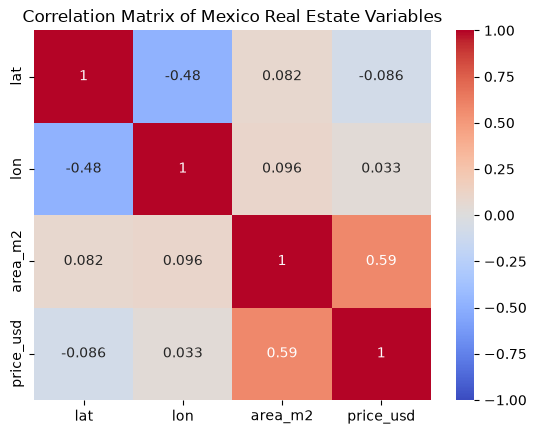

In [8]:
correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Mexico Real Estate Variables")
plt.show()


In [9]:
df.groupby("state")

In [10]:
state_correlations = df.groupby("state").apply(
    lambda group: group["area_m2"].corr(group["price_usd"]),
    include_groups=False
)

state_correlations.sort_values(ascending=False)

state
Zacatecas                          1.000000
Colima                             0.988235
Sonora                             0.911524
Durango                            0.909258
Baja California Sur                0.880583
Aguascalientes                     0.873437
San Luis Potosí                    0.855196
Morelos                            0.849808
Campeche                           0.824161
Hidalgo                            0.822157
Querétaro                          0.819374
Nayarit                            0.774295
Puebla                             0.772550
Tamaulipas                         0.763998
Chiapas                            0.755961
Tlaxcala                           0.743335
Yucatán                            0.740413
Guerrero                           0.674457
Baja California                    0.658334
Chihuahua                          0.636292
Estado de México                   0.630110
Quintana Roo                       0.626626
Sinaloa                   

In [11]:
df["state"].value_counts()

state
Distrito Federal                   303
Estado de México                   179
Yucatán                            171
Morelos                            160
Querétaro                          128
Veracruz de Ignacio de la Llave    117
Puebla                              95
Nuevo León                          83
Jalisco                             60
Chiapas                             55
San Luis Potosí                     55
Guerrero                            49
Tamaulipas                          48
Quintana Roo                        38
Baja California                     29
Sinaloa                             26
Tabasco                             20
Chihuahua                           20
Hidalgo                             17
Baja California Sur                 15
Sonora                              12
Guanajuato                          12
Aguascalientes                      10
Nayarit                              9
Durango                              7
Tlaxcala           

## 1. Correlation and Variable Relationships

### 1.1 Load and inspect the data

The cleaned Mexico real estate dataset contains 1,736 property listings and six columns: `property_type`, `state`, `lat`, `lon`, `area_m2`, and `price_usd`.

All six columns contain 1,736 non-null values. The dataset has four numeric columns and two text columns.

### 1.2 National Pearson correlation

Pearson's correlation coefficient was used to investigate the linear relationship between property area and price.

The correlation between `area_m2` and `price_usd` was approximately **0.586**, indicating a moderate positive linear relationship. Larger properties generally tend to have higher prices, although properties of similar sizes can still have substantially different prices.

Correlation does not establish causation, and property area alone does not explain all price variation.

### 1.3 Correlation matrix and heatmap

A correlation matrix was calculated for the four numeric variables: `lat`, `lon`, `area_m2`, and `price_usd`.

Key findings:

- `area_m2` and `price_usd` have a positive correlation of approximately 0.586.
- `lat` and `lon` have a negative correlation of approximately -0.480.
- The correlations between the individual coordinates and price are close to zero.
- The correlations between area and the individual coordinates are also close to zero.

These coordinate correlations do not establish that location is unimportant. Simple linear correlations may not capture geographic patterns or differences between states.

### 1.4 Correlation by state

The relationship between area and price was calculated separately for each state.

The results varied between states. For example, Yucatán had a correlation of approximately 0.740, while Distrito Federal had a correlation of approximately 0.411.

Sample sizes must be considered when interpreting these results. Zacatecas and Oaxaca each contain only two listings, producing correlations of +1.000 and -1.000 respectively. These extreme values are not reliable evidence of statewide pricing patterns.

**Interim conclusion:** The national area–price relationship varies across state-level groups, and correlations from very small samples require particular caution.

In [12]:
df.groupby("property_type").apply(
    lambda group: group["area_m2"].corr(group["price_usd"]),
    include_groups=False
)

property_type
apartment    0.519021
house        0.719280
dtype: float64

### 1.5 Correlation by property type

The Pearson correlation between property area and price was calculated separately for apartments and houses.

- **Apartments:** The correlation was approximately 0.519, indicating a moderate positive linear relationship between area and price.
- **Houses:** The correlation was approximately 0.719, indicating a stronger positive linear relationship than for apartments.

The area–price relationship is stronger for houses than for apartments in this dataset. This does not necessarily mean houses are more expensive overall, because correlation measures the strength and direction of a relationship rather than average price levels.

These findings describe the observed listings and do not establish causation.

In [13]:
df["price_per_m2"] = df["price_usd"] / df["area_m2"]

In [14]:
df[["area_m2", "price_usd", "price_per_m2"]].head()

,area_m2,price_usd,price_per_m2
0,150.0,67965.56,453.103733
1,186.0,63223.78,339.912796
2,82.0,84298.37,1028.028902
3,150.0,94308.80,628.725333
4,205.0,105191.37,513.128634


### 1.6 Feature engineering: Price per square metre

A new variable, `price_per_m2`, was created by dividing each property's total price (`price_usd`) by its area (`area_m2`).

This feature represents the price of one square metre of property and allows us to compare properties of different sizes on a common basis.

For example, a property priced at $67,965.56 with an area of 150 m² has a price of approximately $453.10 per square metre.

This derived variable will be used to investigate the relationship between property size and price per square metre.

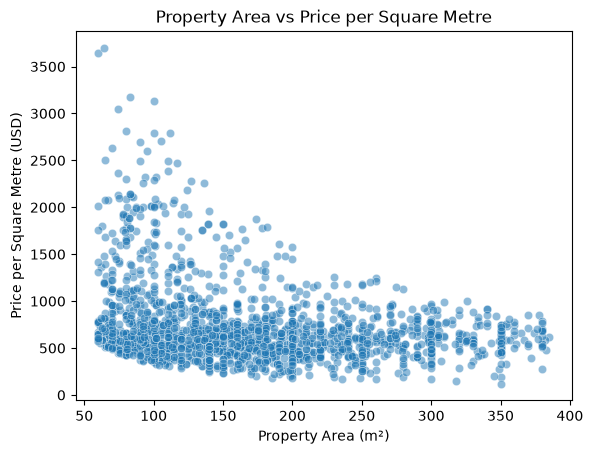

In [15]:
sns.scatterplot(
    data=df,
    x="area_m2",
    y="price_per_m2",
    alpha=0.5
)

plt.title("Property Area vs Price per Square Metre")
plt.xlabel("Property Area (m²)")
plt.ylabel("Price per Square Metre (USD)")
plt.show()

#### 1.7 Relationship between property area and price per square metre

A scatterplot was created to examine the relationship between property area (`area_m2`) and price per square metre (`price_per_m2`).

The plot shows a general downward, curved pattern: price per square metre tends to decrease as property area increases.

This suggests that the relationship is not purely linear. Pearson correlation measures linear relationships, so it may not fully capture this curved pattern.

Price per square metre provides a useful alternative perspective because it allows properties of different sizes to be compared on a common basis. However, this metric alone does not explain all price differences, and the observed pattern does not establish causation.

**Key lesson:** Correlation is a useful starting point for analysis, but visualisations are also important because they can reveal patterns that a single correlation coefficient may not capture.